# 🧩 Subgraphs: Compose a Graph Inside Another Graph

## Learning Objectives
In this notebook, you will learn:
1. **A subgraph on its own** - compile a small tool-calling graph and invoke it directly, before it is nested inside anything else
2. **Shared state** - add that compiled graph as a node of a parent when both graphs use the same state schema
3. **State transformation** - when the parent and child use different keys, wrap the subgraph in a node that maps state across the boundary

## Prerequisites
- Familiarity with `StateGraph`, `MessagesState`, and conditional edges (see modules [01](../../m09_langgraph_core/README.md)–[02](../../m09_langgraph_core/README.md))
- An LLM configured via `aied_helpers.get_openai_llm` (or swap in any other `aied_helpers` factory)
- `OPENAI_API_KEY` set in a `.env` file at the project root


---
## 📦 Part 0: Environment Setup

Load environment variables. The chat model itself is created in Part 1, because it is bound to the weather tool that the subgraph calls.


In [1]:
# ============================================================================
# ENVIRONMENT SETUP: Imports and API Keys
# ============================================================================
from typing import Literal

from typing_extensions import TypedDict

from dotenv import find_dotenv, load_dotenv
from IPython.display import Image, display
from langchain_core.messages import HumanMessage
from langchain_core.runnables.graph import MermaidDrawMethod
from langchain_core.tools import tool
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode

from aied_helpers import get_openai_llm

# Load API keys from the project's .env file
load_dotenv(find_dotenv(usecwd=True))

print("✅ Environment ready.")


✅ Environment ready.


---
## 🔧 Part 1: A Subgraph on Its Own

A subgraph is an ordinary compiled graph. This part builds one that answers a weather question: an agent node calls the model, a tools node runs `get_weather`, and a conditional edge loops until the model stops requesting tools. Nothing here knows about a parent graph yet.

### Key Concepts:
- **Compiled graph**: `workflow.compile()` returns a runnable you can `invoke` on its own
- **`MessagesState`**: the subgraph's only channel is `messages`, appended by the messages reducer
- **Tool loop**: `should_continue` sends tool calls to `"tools"` and otherwise ends the graph


### 1.1 The Weather Tool and the Model

`get_weather` is a stand-in for a real weather API: Munich is cloudy, every other city is sunny. Binding the tool to the model lets the agent request it by name.


In [2]:
# ============================================================================
# TOOL + MODEL: Weather Lookup Bound to the Chat Model
# ============================================================================
@tool
def get_weather(location: str):
    """Call to get the current weather."""
    if location.lower() in ["munich"]:
        return "It's 15 degrees Celsius and cloudy."
    else:
        return "It's 32 degrees Celsius and sunny."


tools = [get_weather]
model = get_openai_llm(model="gpt-4o-mini").bind_tools(tools)

print("🤖 LLM initialized: gpt-4o-mini (1 tool bound)")


🤖 LLM initialized: gpt-4o-mini (1 tool bound)


### 1.2 The Agent Node and the Router

`call_model` appends one model response. `should_continue` reads the last message: tool calls go to the tools node, anything else ends the run.


In [3]:
# ============================================================================
# NODES: call_model and should_continue
# ============================================================================
def call_model(state: MessagesState):
    messages = state["messages"]
    response = model.invoke(messages)
    return {"messages": [response]}


def should_continue(state: MessagesState) -> Literal["tools", END]:
    messages = state["messages"]
    last_message = messages[-1]
    if last_message.tool_calls:
        return "tools"
    return END


### 1.3 Compile the Subgraph

`START → agent`, then either `agent → tools → agent` or `agent → END`. `ToolNode` executes whatever tool calls the agent just emitted.


In [4]:
# ============================================================================
# GRAPH CONSTRUCTION: Weather Subgraph
# ============================================================================
subgraph_workflow = StateGraph(MessagesState)
tool_node = ToolNode(tools)

subgraph_workflow.add_node("agent", call_model)
subgraph_workflow.add_node("tools", tool_node)
subgraph_workflow.add_edge(START, "agent")
subgraph_workflow.add_conditional_edges("agent", should_continue)
subgraph_workflow.add_edge("tools", "agent")

subgraph = subgraph_workflow.compile()
print("✅ Subgraph compiled.")


✅ Subgraph compiled.


### 1.4 Draw the Subgraph

`get_graph().draw_mermaid_png()` renders the nodes and edges you just added. This call needs network access to the Mermaid rendering API.


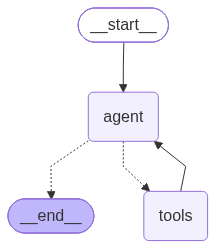

In [5]:
# ============================================================================
# VISUALIZE: Subgraph Nodes and Edges
# ============================================================================
display(
    Image(
        subgraph.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API,
        )
    )
)


### 1.5 Invoke the Subgraph Directly

Pass a `messages` list, the same shape `MessagesState` expects. The returned state is the full transcript: human question, tool call, tool result, and the model's final answer.


In [6]:
# ============================================================================
# RUN: Subgraph Alone
# ============================================================================
subgraph.invoke({"messages": [HumanMessage(content="How is the weather in Munich?")]})


{'messages': [HumanMessage(content='How is the weather in Munich?', additional_kwargs={}, response_metadata={}, id='19b703a7-51b1-4a42-ada6-5d724b1f289a'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 51, 'total_tokens': 66, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_f19e0a6e53', 'id': 'chatcmpl-EY8Wbo4ps5QONqQ2PKkVSLqCiyu9Q', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a12fe0-d817-7c51-a78c-566234fd1444-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Munich'}, 'id': 'call_AzFWMStKXAQoXVYckUu

In [15]:
result = subgraph.invoke({"messages": [HumanMessage(content="How is the weather in Munich?")]})
result["messages"][-1].content

'The weather in Munich is currently 15 degrees Celsius and cloudy.'

---
## 🔗 Part 2: Shared State — Embed the Subgraph as a Node

When the parent uses the same schema as the child, add the compiled subgraph with `add_node`. LangGraph treats it like any other node: the parent's `messages` channel is the subgraph's `messages` channel. No translation function is required.

### Key Concepts:
- **Same keys**: direct embedding works because both graphs read and write `messages`
- **Compiled graph as a node**: `add_node("subgraph", subgraph)` nests the Part 1 graph inside the parent
- **Ordinary edges**: `START → start → subgraph` is the whole parent


### 2.1 A Pass-Through Parent Node

`start_node` stands in for parent work that happens before the nested graph. It returns the state it received, so the messages the caller sent are still there when the subgraph runs.


In [7]:
# ============================================================================
# NODE: start_node - Pass Parent State Through
# ============================================================================
def start_node(state: MessagesState):
    return state


### 2.2 Build the Parent

The second argument to `add_node` is the compiled object from Part 1, not a new function.


In [8]:
# ============================================================================
# GRAPH CONSTRUCTION: Parent Shares MessagesState
# ============================================================================
main_graph = StateGraph(MessagesState)
main_graph.add_node("start", start_node)
main_graph.add_node("subgraph", subgraph)
main_graph.add_edge(START, "start")
main_graph.add_edge("start", "subgraph")

graph = main_graph.compile()
print("✅ Parent compiled (shared MessagesState).")


✅ Parent compiled (shared MessagesState).


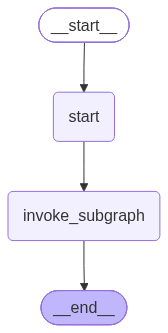

In [14]:
graph

### 2.3 Run the Parent

The caller still sends `messages`. The subgraph runs as the `"subgraph"` node and writes its reply back onto that same channel.


In [9]:
# ============================================================================
# RUN: Parent Invokes the Embedded Subgraph
# ============================================================================
graph.invoke({"messages": [HumanMessage(content="What's the weather in Munich?")]})


{'messages': [HumanMessage(content="What's the weather in Munich?", additional_kwargs={}, response_metadata={}, id='b229a787-1860-4c05-9957-53c793a20c8c'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 50, 'total_tokens': 65, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_f19e0a6e53', 'id': 'chatcmpl-EY8WdhsHSU9kd0dDwNDpSZxaB6QpF', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a12fe0-e7e3-7392-88c0-c13d4d4a9fe3-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Munich'}, 'id': 'call_rhV7lyFmnd50RWQyPhh

---
## 🔄 Part 3: Different Schemas — Transform State at the Boundary

Direct embedding fails when the keys differ. This parent stores the transcript under `parent_messages`. The subgraph from Part 1 still expects `messages`. A wrapper node calls `subgraph.invoke` itself and copies the child's output back onto the parent's key.

### Key Concepts:
- **Key mismatch**: a compiled subgraph added with `add_node` only sees state channels it shares with the parent
- **Wrapper node**: an ordinary function that translates parent state into the child's input and writes the child's output back
- **Child stays unchanged**: the Part 1 subgraph is still invoked with `{"messages": ...}`


### 3.1 The Parent Schema

`ParentState` has one field, `parent_messages`. It does not include `messages`, so the parent and the subgraph no longer line up.


In [10]:
# ============================================================================
# STATE SCHEMA: ParentState (Different Key from the Subgraph)
# ============================================================================
class ParentState(TypedDict):
    parent_messages: list


### 3.2 The Wrapper Node

Read `parent_messages`, hand that list to the subgraph as `messages`, then store the subgraph's `messages` back on `parent_messages`. This overwrites nothing in the child graph — the mapping lives only in the parent.


In [11]:
# ============================================================================
# NODE: invoke_subgraph - Map parent_messages <-> messages
# ============================================================================
def invoke_subgraph(state: ParentState):
    subgraph_output = subgraph.invoke({"messages": state["parent_messages"]})
    state["parent_messages"] = subgraph_output["messages"]
    return state


### 3.3 Build and Run

`start_node` from Part 2 still works here: it returns whatever dict it was given. The new node is `invoke_subgraph`, not the compiled subgraph object.


In [12]:
# ============================================================================
# GRAPH CONSTRUCTION: Parent Transforms State Around the Subgraph
# ============================================================================
main_graph = StateGraph(ParentState)
main_graph.add_node("start", start_node)
main_graph.add_node("invoke_subgraph", invoke_subgraph)
main_graph.add_edge(START, "start")
main_graph.add_edge("start", "invoke_subgraph")

graph = main_graph.compile()
print("✅ Parent compiled (parent_messages mapped onto messages).")


✅ Parent compiled (parent_messages mapped onto messages).


In [13]:
# ============================================================================
# RUN: Caller Sends parent_messages, Not messages
# ============================================================================
graph.invoke(
    {"parent_messages": [HumanMessage(content="What's the weather in Munich?")]}
)


{'parent_messages': [HumanMessage(content="What's the weather in Munich?", additional_kwargs={}, response_metadata={}, id='369f07bb-6655-4f77-81ea-4713cf130bb4'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 50, 'total_tokens': 65, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_f19e0a6e53', 'id': 'chatcmpl-EY8WfCZW5pIcBeQ1X2bFaC1jMaDCt', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a12fe0-eeba-7f30-bd6e-d3728d458676-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Munich'}, 'id': 'call_YyV10cFXhXWC

---
## 📝 Summary

In this notebook, we learned:

### 1. A Subgraph on Its Own
- A subgraph is a compiled `StateGraph`. Invoke it directly to confirm its own input and output before nesting it
- This one is a short tool loop: `agent` calls the model, `tools` runs `get_weather`, and `should_continue` decides whether to loop

### 2. Shared State
- `add_node("subgraph", subgraph)` embeds a compiled graph when the parent and child share state keys
- With `MessagesState` on both sides, `messages` flows into the child and the child's updates flow back out. No adapter node is required

### 3. Different Schemas
- Different keys mean you cannot drop the compiled graph in as a node and expect the channels to line up
- A wrapper node calls `subgraph.invoke` with the child's schema and copies the result onto the parent's schema
- The child graph stays the same. Only the parent knows about `parent_messages`

### Next Steps
- Continue to **[09_async_and_streaming](../README.md)** to run a graph with `ainvoke` and to stream updates and messages as nodes execute
